# Benchmark: graph sizes and computational scalability

Numerical results are read from `results/analysis/`. Figures are drawn inline; this notebook does not refit models or rerun graph metrics or statistical comparisons.


## Reported graph sizes: 10, 15, 20 and 30 variables


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'runs/run_model.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from inside the repository.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path[:0] = [str(ROOT / 'analysis'), str(ROOT / 'runs')]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()


### Performance by graph size


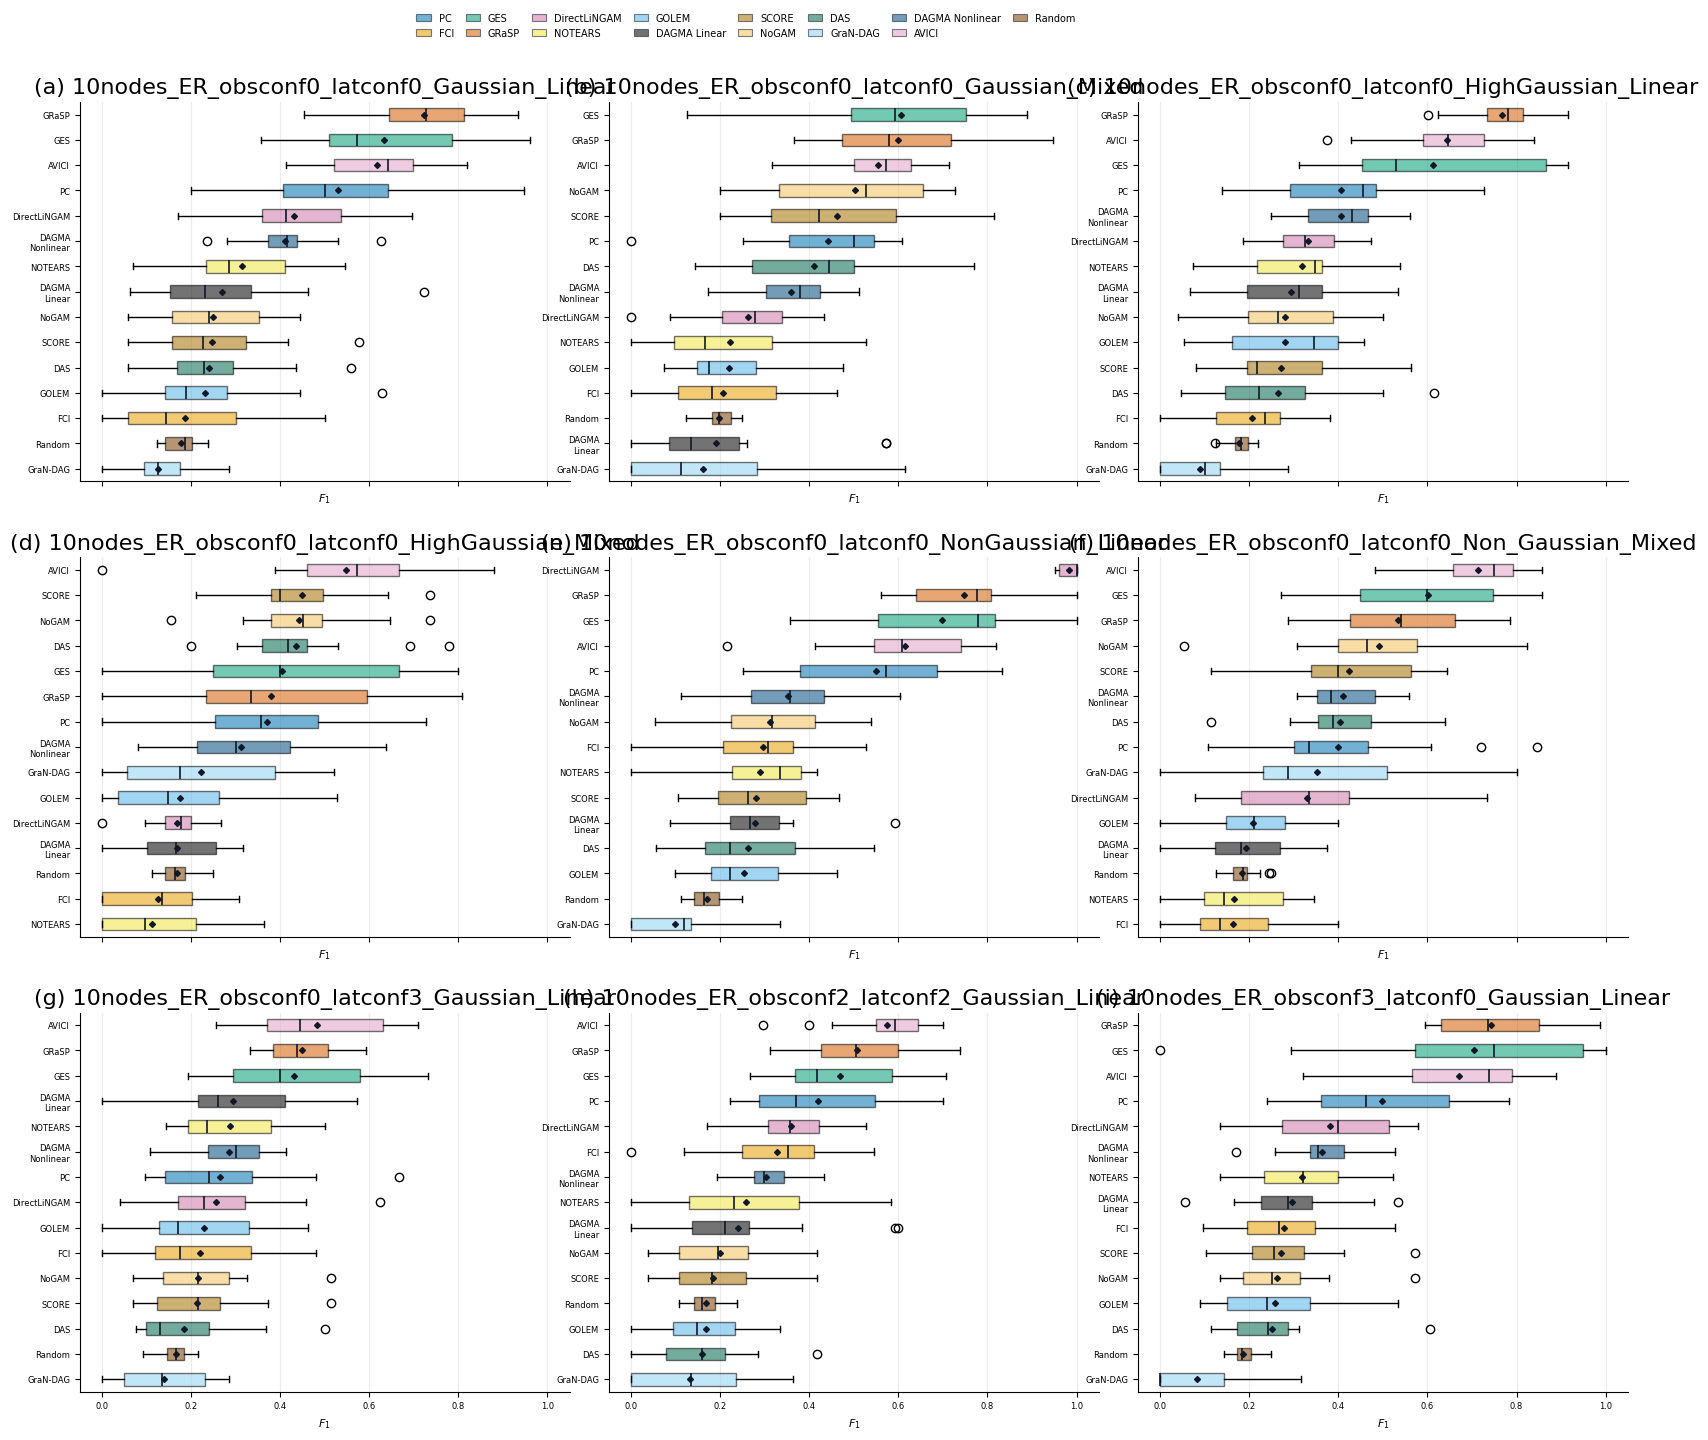

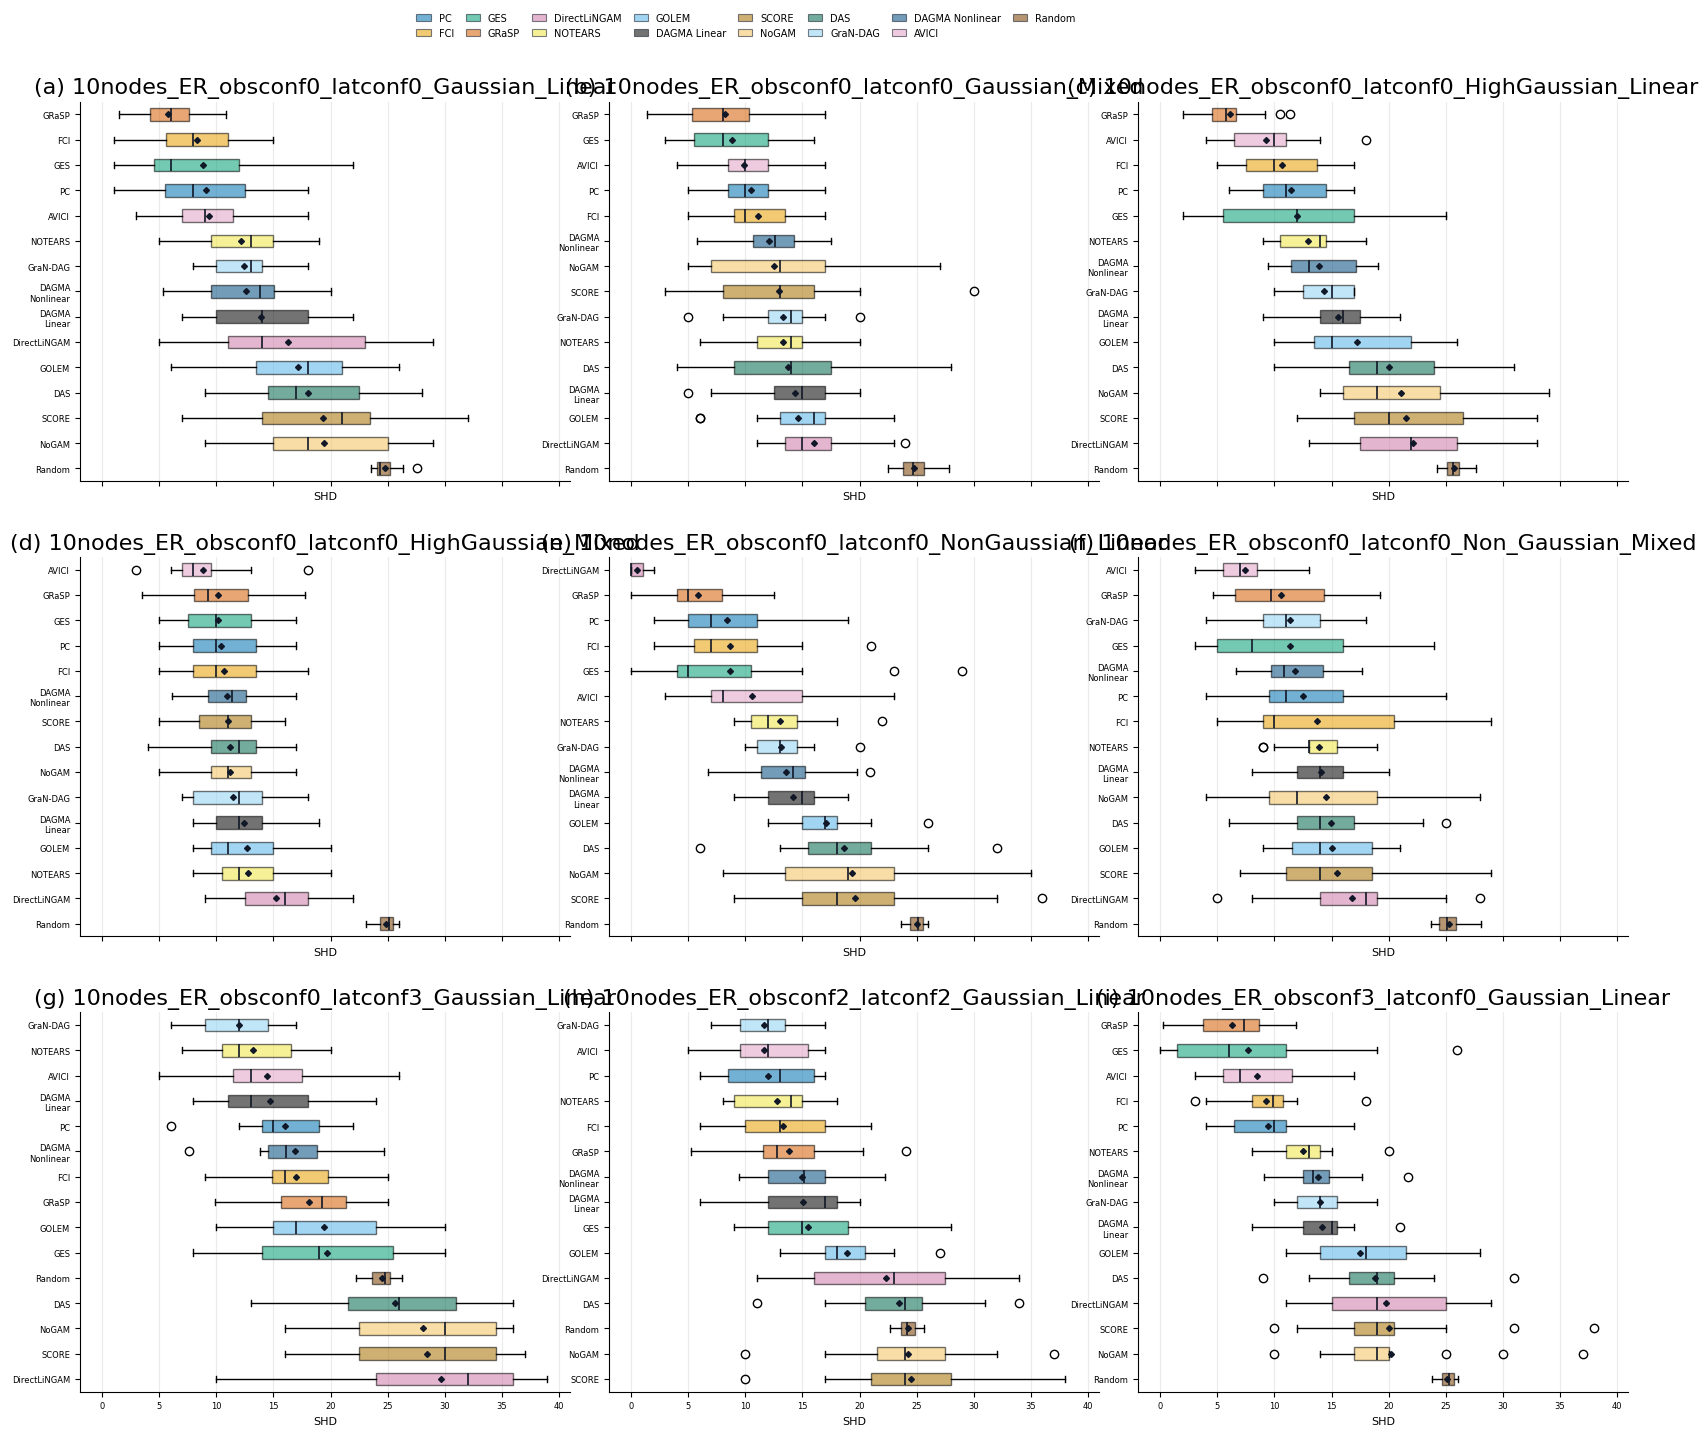

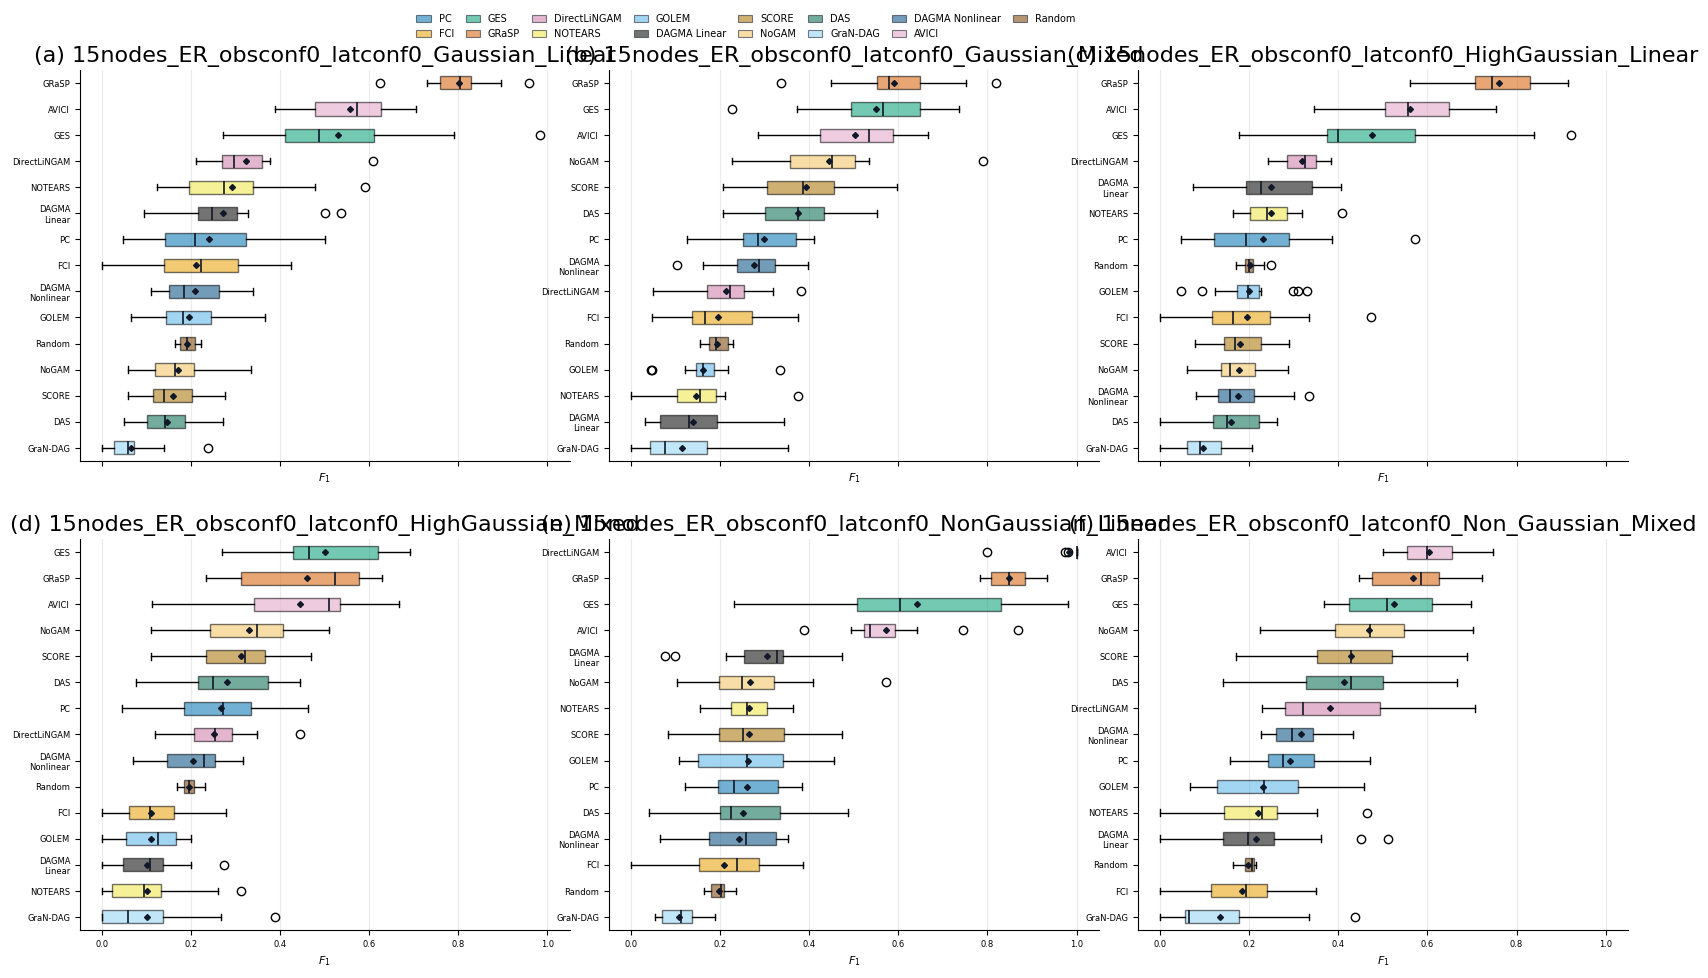

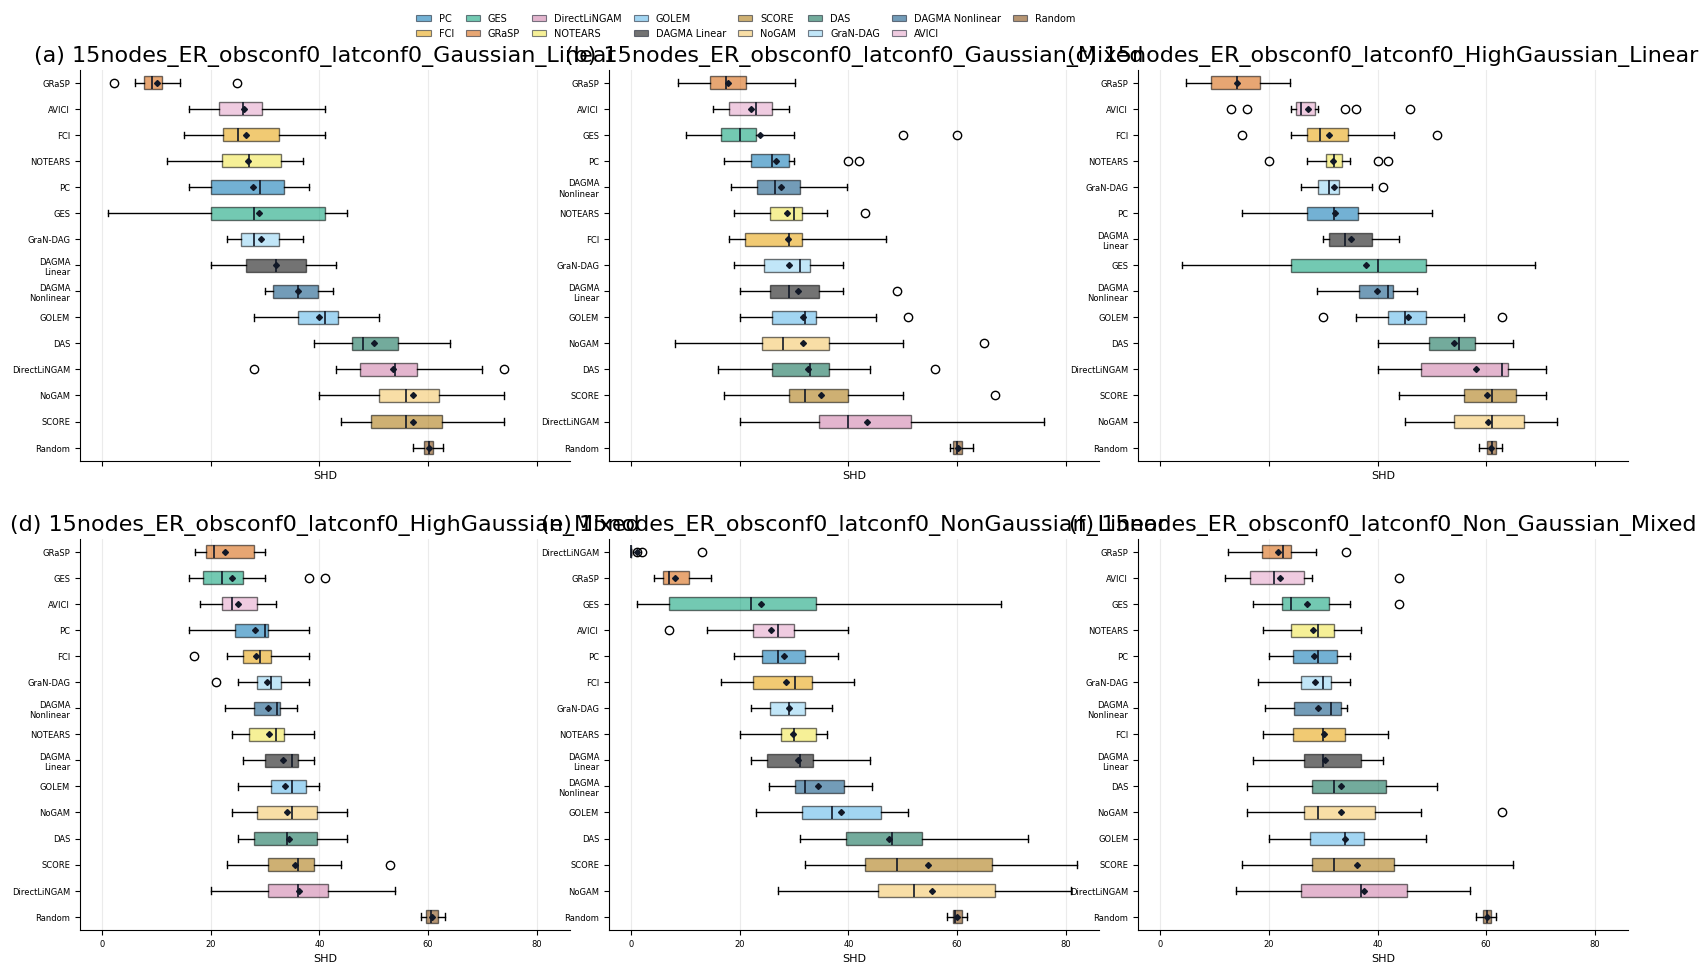

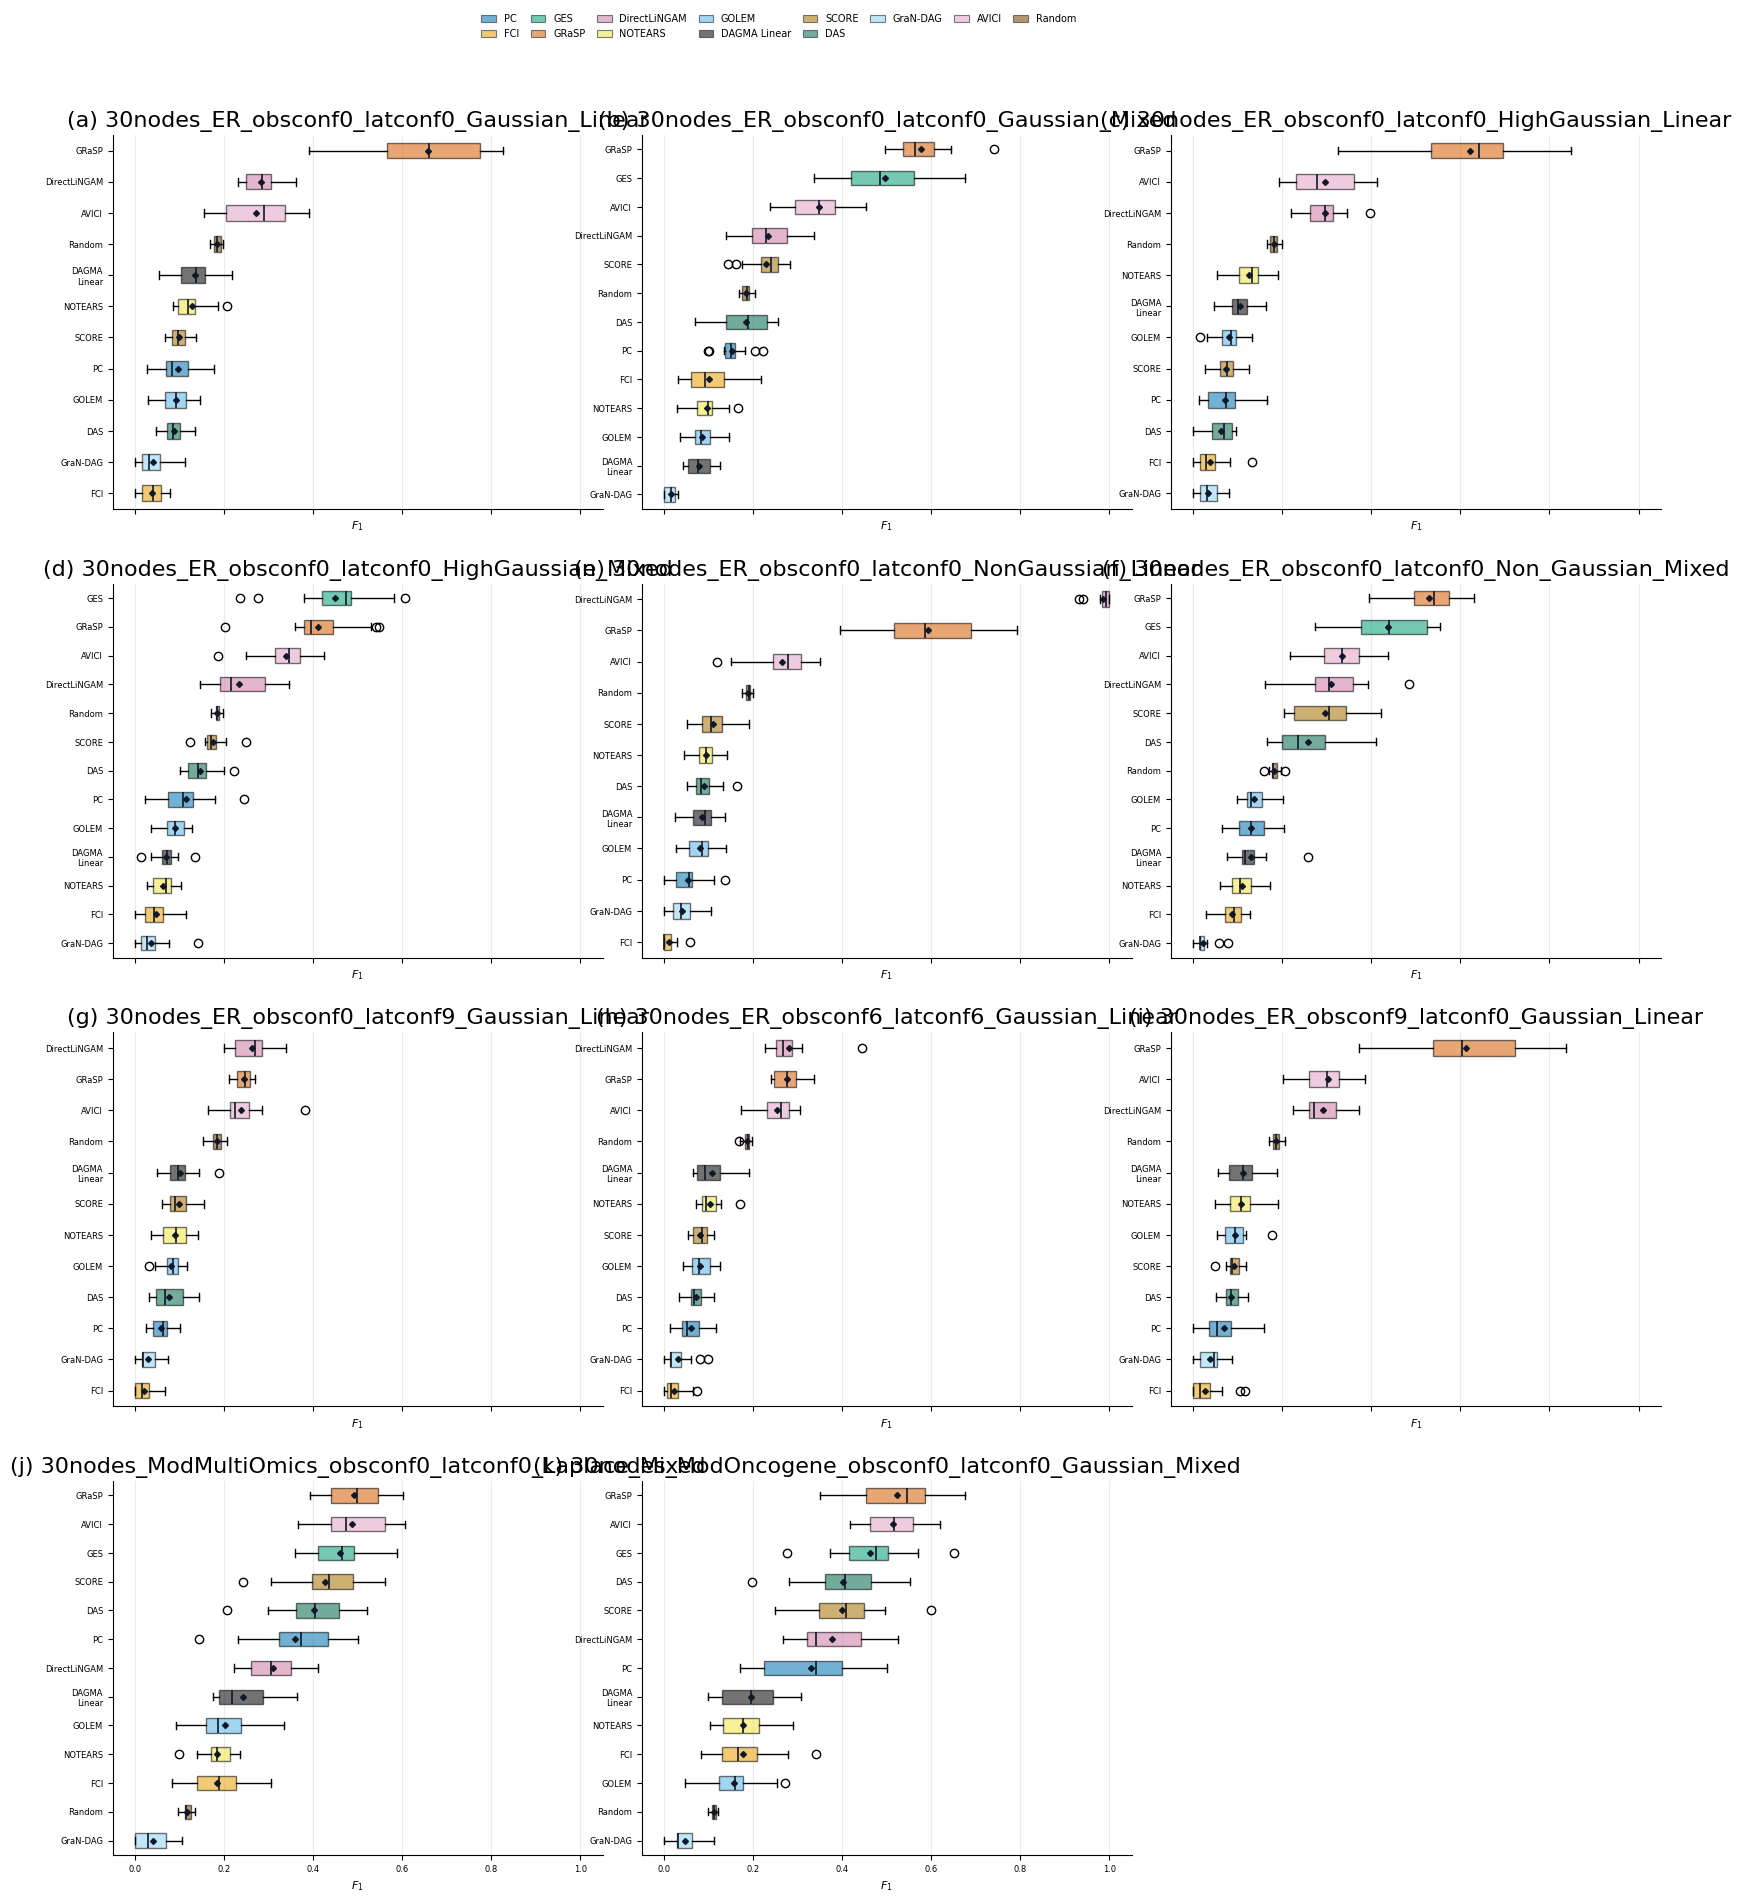

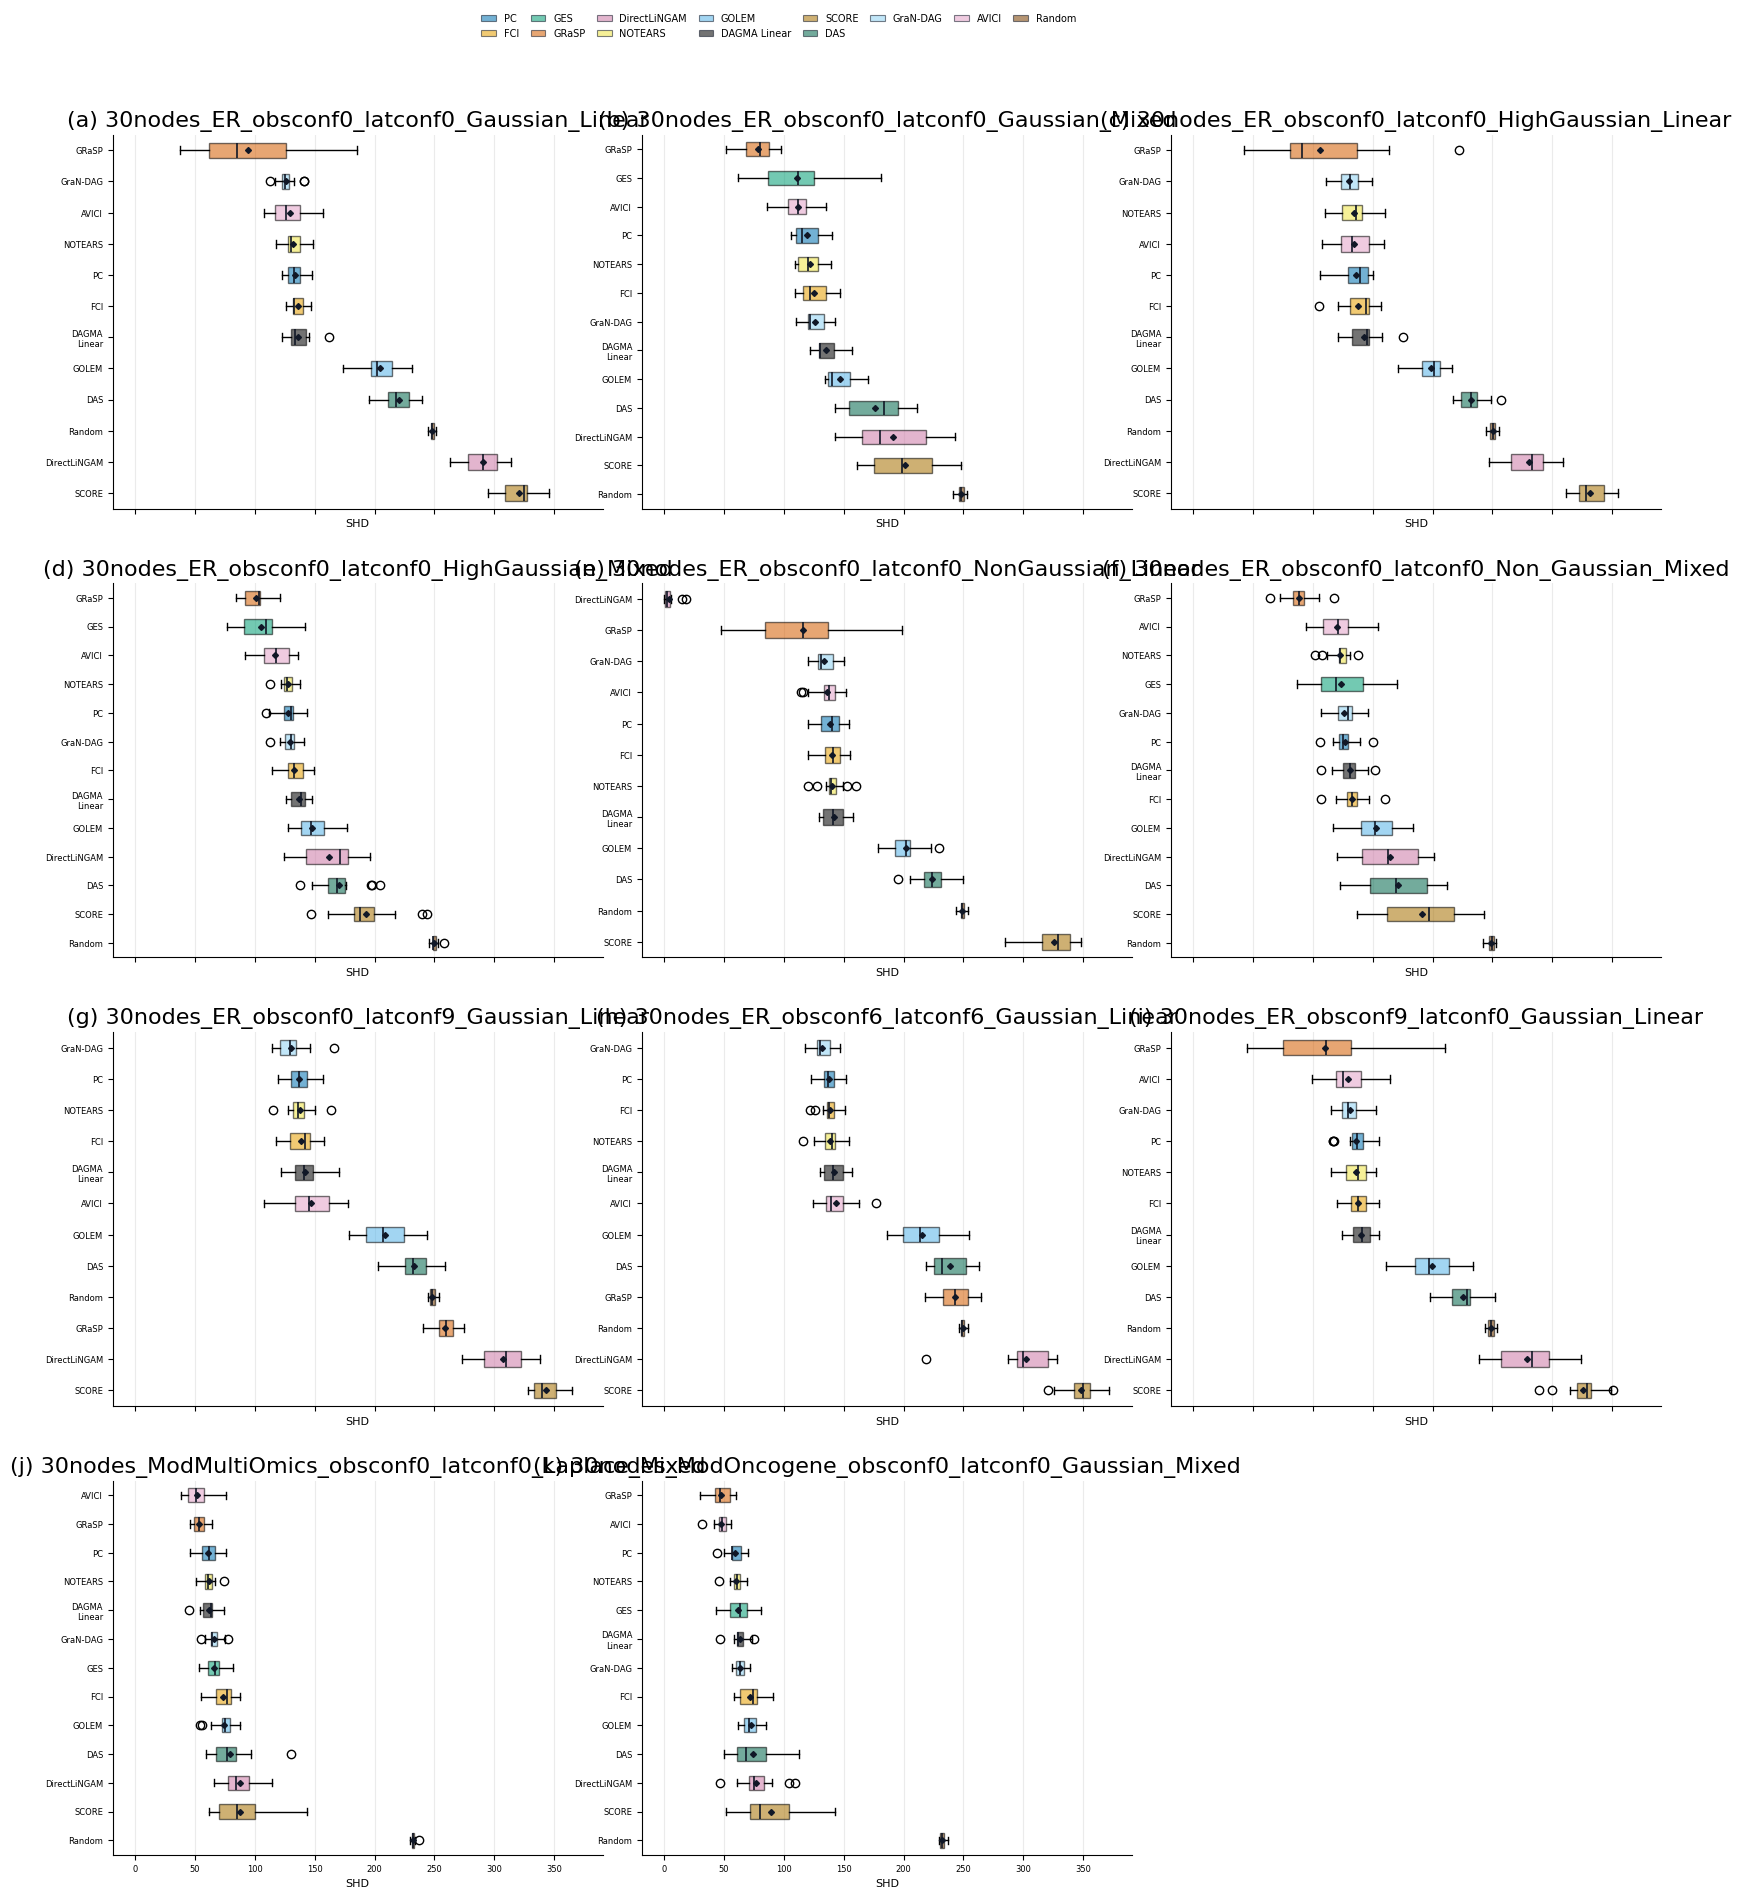

In [2]:
graph_sizes = th.prepare_metrics(th.load_graph_size_results())
for size in sorted(graph_sizes.n_nodes.dropna().unique()):
    frame = graph_sizes.loc[graph_sizes.n_nodes.eq(size)]
    for metric in ('f1', 'SHD'):
        specs = [{'title': family, 'datasets': family} for family in sorted(frame.dataset.unique())]
        fig, _, _ = fv.plot_metric_boxplot_grid(th.visualization_data(frame), specs, metric=metric, coverage_policy='all', ncols=3, figsize=(18, 5 * ((len(specs) + 2) // 3)), font_size=8)
        display(fig)
        plt.close(fig)


### Mean and standard deviation by graph size

Model runs are averaged within each dataset instance. The tables report the mean and sample standard deviation across dataset instances, using completed runs. Dashes indicate no completed run. High-variance Gaussian linear conditions are excluded from these comparison tables.


In [3]:
tables = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")
size_tables = tables['size_tables']
for (size, metric), table in size_tables.items():
    print(size, metric)
    display(table)


10.0 f1
10.0 SHD
15.0 f1
15.0 SHD
20.0 f1
20.0 SHD
30.0 f1
30.0 SHD


dataset,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10nodes_ER_obsconf0_latconf0_Gaussian_Mixed,10nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,10nodes_ER_obsconf0_latconf0_NonGaussian_Linear,10nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,10nodes_ER_obsconf0_latconf3_Gaussian_Linear,10nodes_ER_obsconf2_latconf2_Gaussian_Linear,10nodes_ER_obsconf3_latconf0_Gaussian_Linear
model,,,,,,,,
AVICI,0.617 ± 0.125,0.554 ± 0.111,0.548 ± 0.202,0.615 ± 0.158,0.713 ± 0.118,0.483 ± 0.147,0.574 ± 0.114,0.670 ± 0.177
DAGMA_Linear,0.269 ± 0.170,0.190 ± 0.171,0.168 ± 0.113,0.279 ± 0.118,0.194 ± 0.105,0.293 ± 0.160,0.240 ± 0.170,0.295 ± 0.123
DAGMA_Nonlinear,0.411 ± 0.096,0.359 ± 0.095,0.311 ± 0.147,0.352 ± 0.138,0.410 ± 0.080,0.284 ± 0.088,0.303 ± 0.065,0.363 ± 0.085
DAS,0.240 ± 0.132,0.410 ± 0.184,0.436 ± 0.146,0.263 ± 0.150,0.404 ± 0.130,0.184 ± 0.121,0.159 ± 0.111,0.251 ± 0.116
DirectLiNGAM,0.432 ± 0.148,0.263 ± 0.122,0.168 ± 0.067,0.983 ± 0.022,0.330 ± 0.186,0.256 ± 0.152,0.358 ± 0.098,0.380 ± 0.138
FCI,0.187 ± 0.158,0.206 ± 0.157,0.125 ± 0.104,0.297 ± 0.139,0.162 ± 0.125,0.220 ± 0.164,0.328 ± 0.147,0.277 ± 0.130
GES,0.634 ± 0.198,0.606 ± 0.200,0.404 ± 0.266,0.698 ± 0.189,0.600 ± 0.196,0.430 ± 0.175,0.468 ± 0.141,0.704 ± 0.297
GOLEM,0.231 ± 0.156,0.219 ± 0.116,0.175 ± 0.160,0.253 ± 0.117,0.207 ± 0.106,0.229 ± 0.141,0.167 ± 0.097,0.258 ± 0.135
GRaSP,0.723 ± 0.134,0.599 ± 0.177,0.379 ± 0.258,0.746 ± 0.124,0.534 ± 0.155,0.450 ± 0.086,0.506 ± 0.118,0.743 ± 0.128


dataset,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10nodes_ER_obsconf0_latconf0_Gaussian_Mixed,10nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,10nodes_ER_obsconf0_latconf0_NonGaussian_Linear,10nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,10nodes_ER_obsconf0_latconf3_Gaussian_Linear,10nodes_ER_obsconf2_latconf2_Gaussian_Linear,10nodes_ER_obsconf3_latconf0_Gaussian_Linear
model,,,,,,,,
AVICI,9.333 ± 4.012,9.867 ± 3.399,8.867 ± 3.399,10.600 ± 6.010,7.400 ± 3.180,14.400 ± 6.311,11.667 ± 3.773,8.467 ± 4.257
DAGMA_Linear,13.933 ± 5.049,14.333 ± 4.530,12.467 ± 3.226,14.133 ± 2.949,14.067 ± 3.390,14.667 ± 4.746,15.067 ± 4.250,14.200 ± 3.121
DAGMA_Nonlinear,12.596 ± 4.376,12.076 ± 3.402,10.960 ± 2.860,13.573 ± 4.023,11.769 ± 3.204,16.876 ± 4.239,14.951 ± 3.842,13.822 ± 3.210
DAS,18.000 ± 5.606,13.733 ± 6.341,11.200 ± 3.427,18.600 ± 6.127,14.933 ± 5.216,25.667 ± 6.532,23.467 ± 5.553,18.800 ± 4.989
DirectLiNGAM,16.267 ± 7.245,16.000 ± 3.873,15.267 ± 3.936,0.467 ± 0.640,16.800 ± 6.062,29.667 ± 8.139,22.333 ± 7.078,19.733 ± 6.135
FCI,8.338 ± 3.998,11.067 ± 3.494,10.667 ± 3.867,8.667 ± 4.995,13.684 ± 7.294,16.991 ± 3.904,13.267 ± 4.773,9.293 ± 3.483
GES,8.867 ± 6.653,8.800 ± 3.950,10.133 ± 3.623,8.667 ± 8.006,11.400 ± 7.670,19.667 ± 7.218,15.467 ± 5.055,7.667 ± 8.042
GOLEM,17.133 ± 5.998,14.600 ± 4.517,12.667 ± 3.848,17.067 ± 3.494,15.000 ± 3.836,19.400 ± 6.423,18.933 ± 3.327,17.533 ± 5.055
GRaSP,5.760 ± 2.543,8.253 ± 4.182,10.124 ± 3.732,5.809 ± 3.113,10.609 ± 4.756,18.124 ± 4.834,13.809 ± 4.581,6.320 ± 3.275


dataset,15nodes_ER_obsconf0_latconf0_Gaussian_Linear,15nodes_ER_obsconf0_latconf0_Gaussian_Mixed,15nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,15nodes_ER_obsconf0_latconf0_NonGaussian_Linear,15nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed
model,,,,,
AVICI,0.557 ± 0.099,0.503 ± 0.112,0.445 ± 0.152,0.573 ± 0.113,0.604 ± 0.076
DAGMA_Linear,0.270 ± 0.120,0.138 ± 0.083,0.102 ± 0.080,0.304 ± 0.117,0.214 ± 0.143
DAGMA_Nonlinear,0.209 ± 0.073,0.275 ± 0.075,0.204 ± 0.077,0.242 ± 0.097,0.316 ± 0.069
DAS,0.146 ± 0.067,0.374 ± 0.100,0.281 ± 0.105,0.252 ± 0.123,0.412 ± 0.135
DirectLiNGAM,0.322 ± 0.094,0.213 ± 0.083,0.252 ± 0.087,0.984 ± 0.051,0.380 ± 0.138
FCI,0.210 ± 0.137,0.194 ± 0.103,0.110 ± 0.080,0.209 ± 0.111,0.184 ± 0.099
GES,0.529 ± 0.187,0.551 ± 0.134,0.500 ± 0.131,0.642 ± 0.222,0.524 ± 0.113
GOLEM,0.196 ± 0.084,0.162 ± 0.068,0.109 ± 0.069,0.262 ± 0.109,0.231 ± 0.120
GRaSP,0.801 ± 0.080,0.591 ± 0.119,0.461 ± 0.149,0.848 ± 0.049,0.568 ± 0.088


dataset,15nodes_ER_obsconf0_latconf0_Gaussian_Linear,15nodes_ER_obsconf0_latconf0_Gaussian_Mixed,15nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,15nodes_ER_obsconf0_latconf0_NonGaussian_Linear,15nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed
model,,,,,
AVICI,26.200 ± 7.173,22.067 ± 4.978,25.067 ± 4.652,25.667 ± 8.449,22.133 ± 7.873
DAGMA_Linear,31.933 ± 6.808,30.733 ± 7.440,33.267 ± 4.431,30.667 ± 6.904,30.400 ± 7.199
DAGMA_Nonlinear,36.120 ± 4.613,27.573 ± 6.399,30.489 ± 3.933,34.471 ± 6.128,29.093 ± 4.930
DAS,50.067 ± 6.519,32.467 ± 10.350,34.467 ± 6.578,47.400 ± 11.394,33.267 ± 9.122
DirectLiNGAM,53.467 ± 11.600,43.333 ± 13.947,36.333 ± 9.671,1.067 ± 3.348,37.467 ± 13.081
FCI,26.427 ± 7.839,28.889 ± 8.224,28.298 ± 4.891,28.462 ± 6.809,30.129 ± 6.929
GES,28.933 ± 14.048,23.733 ± 13.646,23.867 ± 7.492,23.867 ± 19.033,27.000 ± 7.010
GOLEM,40.000 ± 6.325,31.600 ± 8.500,33.733 ± 4.891,38.600 ± 8.975,34.067 ± 8.884
GRaSP,10.102 ± 5.023,17.813 ± 5.410,22.671 ± 4.867,8.111 ± 3.304,21.702 ± 5.702


dataset,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
model,,,,,,,,,,
AVICI,0.446 ± 0.113,0.480 ± 0.070,0.473 ± 0.077,0.482 ± 0.094,0.503 ± 0.043,0.386 ± 0.078,0.375 ± 0.088,0.477 ± 0.068,0.584 ± 0.105,0.615 ± 0.043
DAGMA_Linear,0.190 ± 0.089,0.138 ± 0.077,0.107 ± 0.078,0.180 ± 0.063,0.162 ± 0.063,0.139 ± 0.053,0.169 ± 0.049,0.183 ± 0.107,0.298 ± 0.125,0.244 ± 0.097
DAGMA_Nonlinear,0.128 ± 0.062,0.298 ± 0.064,0.276 ± 0.067,0.128 ± 0.066,0.331 ± 0.047,0.087 ± 0.042,0.107 ± 0.057,0.110 ± 0.047,0.364 ± 0.041,0.335 ± 0.059
DAS,0.107 ± 0.056,0.295 ± 0.081,0.210 ± 0.083,0.132 ± 0.079,0.303 ± 0.061,0.085 ± 0.049,0.106 ± 0.042,0.118 ± 0.059,0.457 ± 0.113,0.405 ± 0.074
DirectLiNGAM,0.333 ± 0.089,0.208 ± 0.114,0.199 ± 0.085,0.998 ± 0.003,0.375 ± 0.092,0.282 ± 0.072,0.269 ± 0.067,0.316 ± 0.079,0.307 ± 0.084,0.352 ± 0.064
FCI,0.089 ± 0.063,0.154 ± 0.071,0.131 ± 0.065,0.079 ± 0.064,0.165 ± 0.066,0.052 ± 0.043,0.063 ± 0.054,0.089 ± 0.064,0.167 ± 0.096,0.219 ± 0.117
GES,0.394 ± 0.179,0.573 ± 0.093,0.532 ± 0.091,0.444 ± 0.152,0.537 ± 0.149,0.329 ± 0.119,0.304 ± 0.084,0.423 ± 0.201,0.434 ± 0.143,0.485 ± 0.091
GOLEM,0.125 ± 0.048,0.136 ± 0.070,0.103 ± 0.067,0.150 ± 0.091,0.150 ± 0.063,0.109 ± 0.043,0.134 ± 0.066,0.124 ± 0.055,0.318 ± 0.150,0.231 ± 0.083
GRaSP,0.794 ± 0.098,0.586 ± 0.091,0.471 ± 0.085,0.756 ± 0.114,0.605 ± 0.095,0.296 ± 0.042,0.388 ± 0.073,0.781 ± 0.078,0.437 ± 0.110,0.472 ± 0.096


dataset,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
model,,,,,,,,,,
AVICI,56.400 ± 10.582,44.800 ± 6.050,44.933 ± 8.439,53.133 ± 10.803,49.067 ± 10.997,74.200 ± 16.704,68.200 ± 15.303,59.000 ± 12.879,21.667 ± 6.411,17.933 ± 4.559
DAGMA_Linear,60.267 ± 8.996,57.667 ± 8.474,58.933 ± 8.163,61.533 ± 7.558,59.400 ± 8.450,68.533 ± 4.764,66.000 ± 5.043,61.067 ± 10.032,25.400 ± 4.968,25.467 ± 4.357
DAGMA_Nonlinear,72.853 ± 10.923,51.067 ± 6.782,51.849 ± 6.641,70.022 ± 10.395,52.213 ± 7.237,82.973 ± 7.642,77.871 ± 7.974,75.458 ± 10.234,25.200 ± 2.455,25.164 ± 3.706
DAS,104.667 ± 12.821,67.533 ± 13.076,71.533 ± 13.303,100.867 ± 16.013,73.200 ± 12.049,118.400 ± 7.962,115.067 ± 10.173,102.267 ± 15.832,30.933 ± 7.216,34.800 ± 6.505
DirectLiNGAM,105.600 ± 17.357,82.600 ± 23.200,77.933 ± 20.927,0.200 ± 0.414,68.333 ± 18.734,133.867 ± 16.022,135.000 ± 12.107,112.200 ± 21.475,37.600 ± 6.822,36.000 ± 10.556
FCI,59.876 ± 9.870,51.973 ± 10.093,53.858 ± 9.207,62.591 ± 7.203,54.262 ± 10.045,65.658 ± 8.710,66.302 ± 7.654,60.667 ± 8.608,31.467 ± 6.501,32.960 ± 6.478
GES,89.400 ± 34.442,40.200 ± 11.742,41.667 ± 10.998,80.267 ± 27.112,46.600 ± 17.087,116.867 ± 21.074,122.133 ± 15.052,83.000 ± 36.625,30.067 ± 6.923,27.933 ± 5.496
GOLEM,85.533 ± 11.831,62.667 ± 8.600,63.133 ± 10.099,84.400 ± 13.474,68.000 ± 11.850,96.467 ± 12.438,92.733 ± 8.648,86.467 ± 12.212,29.600 ± 7.642,29.933 ± 5.311
GRaSP,23.169 ± 14.850,34.809 ± 8.720,42.182 ± 7.921,28.404 ± 15.398,35.702 ± 9.969,105.942 ± 10.990,86.738 ± 13.556,24.200 ± 11.001,26.511 ± 5.200,24.187 ± 4.325


dataset,30nodes_ER_obsconf0_latconf0_Gaussian_Linear,30nodes_ER_obsconf0_latconf0_Gaussian_Mixed,30nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,30nodes_ER_obsconf0_latconf0_NonGaussian_Linear,30nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,30nodes_ER_obsconf0_latconf9_Gaussian_Linear,30nodes_ER_obsconf6_latconf6_Gaussian_Linear,30nodes_ER_obsconf9_latconf0_Gaussian_Linear,30nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,30nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
model,,,,,,,,,,
AVICI,0.271 ± 0.076,0.347 ± 0.062,0.339 ± 0.062,0.265 ± 0.063,0.335 ± 0.059,0.237 ± 0.051,0.254 ± 0.037,0.302 ± 0.054,0.487 ± 0.081,0.514 ± 0.061
DAGMA_Linear,0.134 ± 0.041,0.079 ± 0.028,0.070 ± 0.028,0.085 ± 0.030,0.129 ± 0.043,0.101 ± 0.036,0.106 ± 0.042,0.112 ± 0.040,0.243 ± 0.062,0.195 ± 0.068
DAS,0.088 ± 0.026,0.183 ± 0.059,0.145 ± 0.035,0.090 ± 0.029,0.258 ± 0.078,0.075 ± 0.033,0.071 ± 0.019,0.085 ± 0.020,0.401 ± 0.084,0.402 ± 0.093
DirectLiNGAM,0.283 ± 0.039,0.232 ± 0.054,0.234 ± 0.064,0.985 ± 0.021,0.309 ± 0.079,0.263 ± 0.044,0.281 ± 0.051,0.292 ± 0.047,0.311 ± 0.062,0.377 ± 0.081
FCI,0.038 ± 0.026,0.101 ± 0.053,0.047 ± 0.034,0.011 ± 0.017,0.087 ± 0.029,0.019 ± 0.019,0.023 ± 0.025,0.027 ± 0.039,0.184 ± 0.066,0.176 ± 0.072
GES,NaN,0.496 ± 0.108,0.450 ± 0.098,NaN,0.437 ± 0.092,NaN,NaN,NaN,0.460 ± 0.064,0.463 ± 0.090
GOLEM,0.092 ± 0.034,0.084 ± 0.031,0.089 ± 0.026,0.081 ± 0.033,0.137 ± 0.030,0.082 ± 0.023,0.080 ± 0.025,0.094 ± 0.032,0.203 ± 0.068,0.156 ± 0.060
GRaSP,0.657 ± 0.132,0.578 ± 0.062,0.411 ± 0.086,0.592 ± 0.111,0.529 ± 0.072,0.244 ± 0.018,0.275 ± 0.031,0.613 ± 0.130,0.492 ± 0.068,0.523 ± 0.100
GraNDAG,0.041 ± 0.033,0.014 ± 0.012,0.035 ± 0.038,0.041 ± 0.028,0.021 ± 0.021,0.029 ± 0.023,0.032 ± 0.028,0.037 ± 0.025,0.041 ± 0.039,0.047 ± 0.031


dataset,30nodes_ER_obsconf0_latconf0_Gaussian_Linear,30nodes_ER_obsconf0_latconf0_Gaussian_Mixed,30nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,30nodes_ER_obsconf0_latconf0_NonGaussian_Linear,30nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,30nodes_ER_obsconf0_latconf9_Gaussian_Linear,30nodes_ER_obsconf6_latconf6_Gaussian_Linear,30nodes_ER_obsconf9_latconf0_Gaussian_Linear,30nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,30nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
model,,,,,,,,,,
AVICI,129.000 ± 15.033,111.933 ± 13.253,116.867 ± 13.876,136.067 ± 11.591,120.467 ± 16.995,146.533 ± 20.110,143.400 ± 13.747,129.133 ± 17.663,52.067 ± 10.653,47.667 ± 5.790
DAGMA_Linear,135.867 ± 10.246,134.867 ± 9.716,136.800 ± 7.821,141.733 ± 9.177,130.667 ± 11.727,141.667 ± 11.412,142.067 ± 9.239,140.000 ± 9.695,61.667 ± 7.537,63.067 ± 6.724
DAS,220.133 ± 12.961,176.200 ± 22.691,170.133 ± 18.597,223.333 ± 13.324,170.867 ± 30.220,233.333 ± 14.331,238.533 ± 15.436,225.733 ± 14.815,78.933 ± 17.613,74.133 ± 18.754
DirectLiNGAM,290.600 ± 15.838,191.000 ± 34.239,162.400 ± 22.915,3.800 ± 5.532,164.267 ± 27.259,307.533 ± 19.052,301.933 ± 27.204,279.200 ± 27.355,87.267 ± 13.931,77.067 ± 15.632
FCI,135.800 ± 6.700,125.036 ± 12.018,132.653 ± 10.401,139.867 ± 10.042,132.529 ± 12.040,138.600 ± 11.885,138.267 ± 7.620,137.933 ± 10.727,73.476 ± 9.726,71.871 ± 9.493
GES,NaN,110.667 ± 34.780,105.067 ± 17.153,NaN,123.500 ± 25.570,NaN,NaN,NaN,65.933 ± 8.216,61.867 ± 10.141
GOLEM,204.867 ± 14.851,146.667 ± 12.122,147.867 ± 14.071,201.800 ± 13.914,152.400 ± 17.602,208.600 ± 19.283,215.800 ± 20.675,199.800 ± 21.227,74.600 ± 10.218,72.333 ± 7.178
GRaSP,94.307 ± 41.587,78.427 ± 13.386,100.627 ± 10.654,115.920 ± 38.996,88.218 ± 12.817,258.742 ± 9.678,242.929 ± 14.873,110.364 ± 45.909,53.547 ± 6.108,47.467 ± 8.849
GraNDAG,126.333 ± 7.706,125.800 ± 9.337,129.067 ± 7.015,133.667 ± 8.731,126.133 ± 10.336,129.933 ± 13.435,131.933 ± 7.896,130.867 ± 12.217,65.800 ± 5.967,63.467 ± 4.470


## Accuracy, runtime and completion as graph size grows

Compares accuracy and runtime across graph sizes. Failed fits remain visible through the coverage policy.


In [4]:
sources = th.load_final_results()
benchmark_data = sources['benchmark_data']
benchmark_with_biological = sources['benchmark_with_biological']


In [5]:
tables = pd.read_pickle(ROOT / "results/analysis/scalability.pkl")
scalability = th.load_scalability_results()


### Runtime


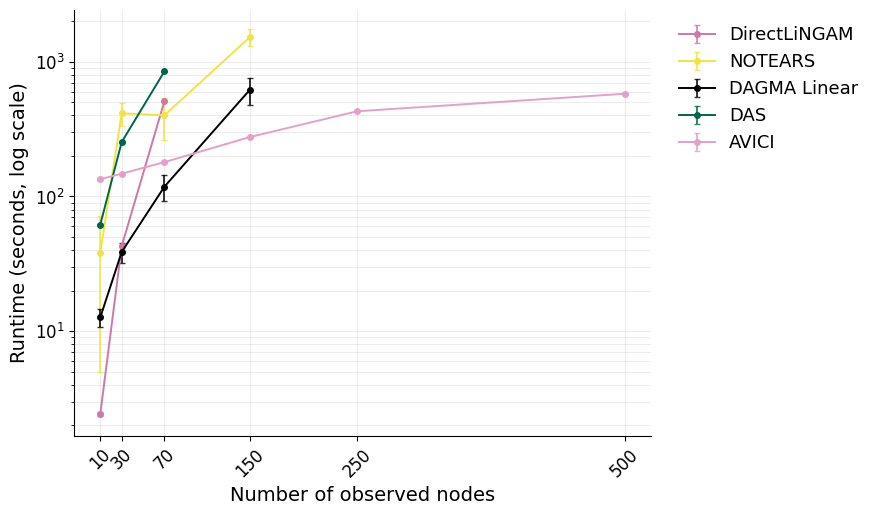

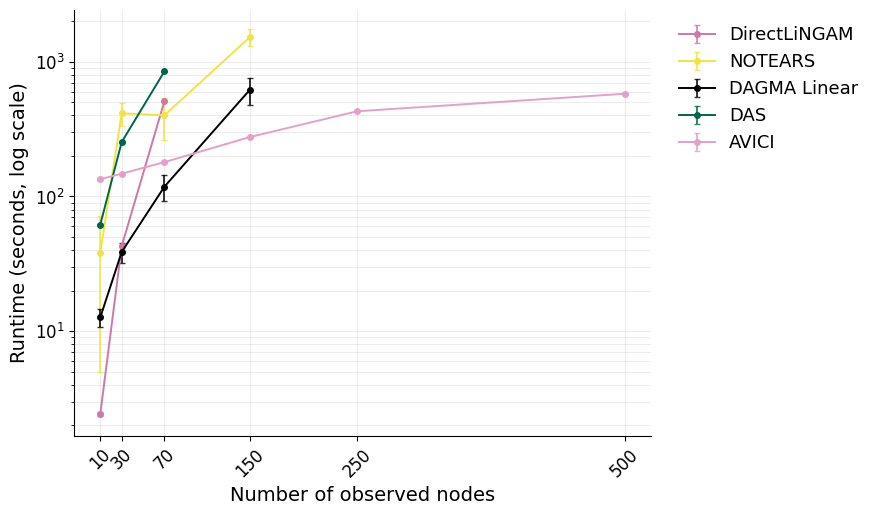

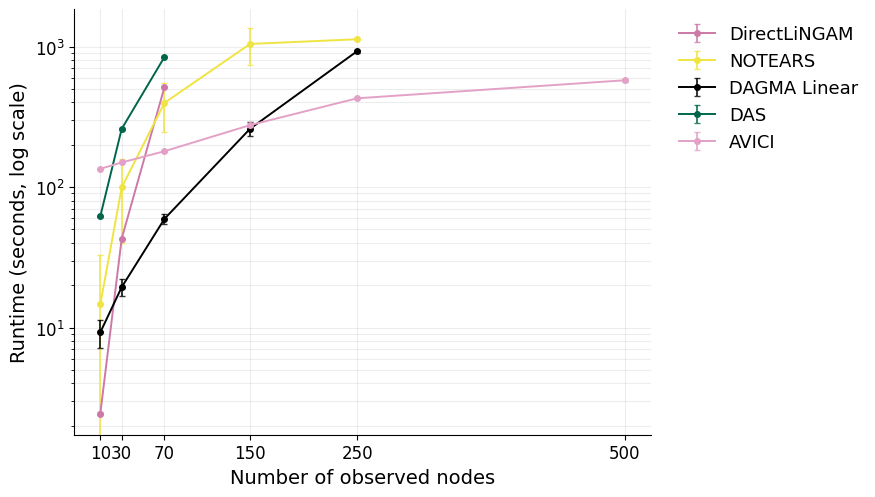

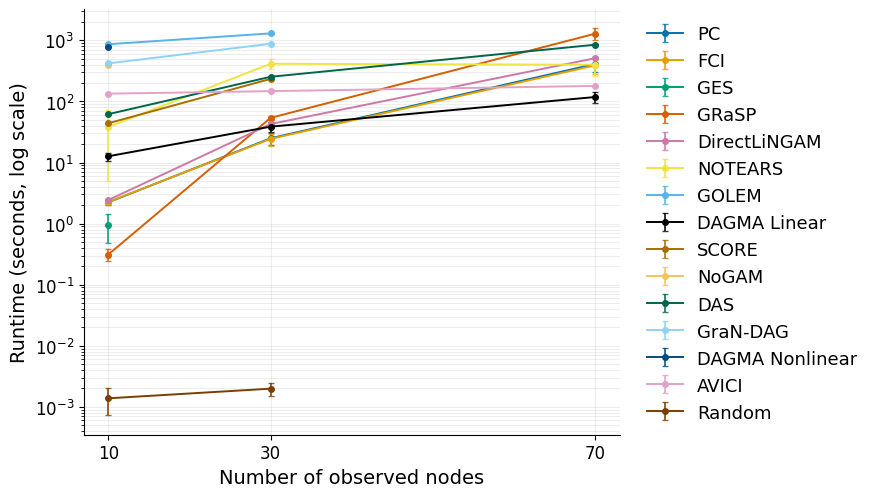

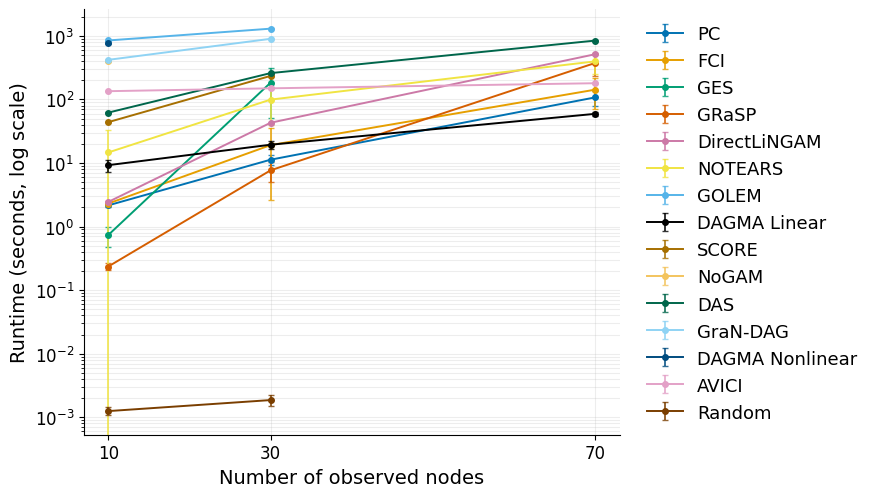

In [6]:
_, _, runtime_output = fv.plot_scalability_runtime(benchmark_data, scalability_data=scalability, exclude_n_nodes=(15, 20, 100), top_n_models=5, uncertainty='sd', separate_families=True, show_metric_title=False, show_family_titles=False, zoom_max_nodes=70, show_coverage=False, errorbar_alpha=0.8, font_size=14, figsize=(9, 5.2))
runtime_fig = runtime_output['figures']['er_gaussian_linear']
runtime_output['axes_by_family']['er_gaussian_linear'].tick_params(axis='x', labelrotation=45)
display(runtime_fig)
for figure in runtime_output['figures'].values():
    display(figure)
    plt.close(figure)
for figure in runtime_output.get('zoom_figures', {}).values():
    display(figure)
    plt.close(figure)
for figure in runtime_output.get('coverage_figures', {}).values():
    display(figure)
    plt.close(figure)


### Accuracy tables


In [7]:
tables = pd.read_pickle(ROOT / "results/analysis/scalability.pkl")
scale_summary = tables['scale_summary']
scale_wide = tables['scale_wide']
mixed_wide = tables['mixed_wide']
progression = tables['progression']
display(scale_summary)


,scalability_family,n_nodes,model,mean,std,size,F1
0,er_gaussian_linear,10.0,AVICI,0.616645,0.125270,15,0.617 ± 0.125
1,er_gaussian_linear,10.0,DAGMA_Linear,0.268810,0.169676,15,0.269 ± 0.170
2,er_gaussian_linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15,0.411 ± 0.096
3,er_gaussian_linear,10.0,DAS,0.240082,0.131551,15,0.240 ± 0.132
4,er_gaussian_linear,10.0,DirectLiNGAM,0.431603,0.148130,15,0.432 ± 0.148
...,...,...,...,...,...,...,...
157,er_nongaussian_mixed,250.0,AVICI,0.004961,0.002560,5,0.005 ± 0.003
158,er_nongaussian_mixed,250.0,DAGMA_Linear,0.008212,0.001172,5,0.008 ± 0.001
159,er_nongaussian_mixed,250.0,FCI,0.002273,0.001142,4,0.002 ± 0.001
160,er_nongaussian_mixed,250.0,NOTEARS,0.005025,NaN,1,0.005 ± nan


In [8]:
display(scale_wide)


n_nodes,Model,10,15,20,30,70,100,150,250,500
0,PC,0.53,0.24,0.17,0.10,0.01,0.01,--,--,--
1,FCI,0.19,0.21,0.09,0.04,0.00,0.00,--,--,--
2,GES,0.63,0.53,0.39,--,--,--,--,--,--
3,GRaSP,0.72,0.80,0.79,0.66,0.18,0.09,--,--,--
4,DirectLiNGAM,0.43,0.32,0.33,0.28,0.17,0.12,--,--,--
5,NOTEARS,0.31,0.29,0.19,0.13,0.04,0.02,0.02,--,--
6,GOLEM,0.23,0.20,0.13,0.09,--,--,--,--,--
7,DAGMA Linear,0.27,0.27,0.19,0.13,0.05,0.02,0.01,--,--
8,SCORE,0.25,0.16,0.12,0.10,--,--,--,--,--
9,NoGAM,0.25,0.17,0.12,--,--,--,--,--,--


### Non-Gaussian mixed mechanisms


In [9]:
display(mixed_wide)


n_nodes,Method,10,15,20,30,70,100,150,250,500
0,PC,0.399,0.291,0.229,0.130,0.045,0.028,0.015,—,—
1,FCI,0.162,0.184,0.165,0.087,0.025,0.015,0.008,0.002,—
2,GES,0.600,0.524,0.537,0.437,—,—,—,—,—
3,GRaSP,0.534,0.568,0.605,0.529,0.429,0.383,—,—,—
4,DirectLiNGAM,0.330,0.380,0.375,0.309,0.250,0.292,—,—,—
5,NOTEARS,0.165,0.220,0.150,0.109,0.041,0.024,0.015,0.005,—
6,GOLEM,0.207,0.231,0.150,0.137,—,—,—,—,—
7,DAGMA Linear,0.194,0.214,0.162,0.129,0.052,0.031,0.022,0.008,—
8,SCORE,0.424,0.428,0.339,0.296,—,—,—,—,—
9,NoGAM,0.491,0.468,0.383,—,—,—,—,—,—


### Progression to the next graph size

The two retained families give 30 planned fits per method and size (five generation instances × three model seeds × two families). A method progresses when at least 10 fits finish. This decision concerns the next size; completed fits at the current size remain in the accuracy tables, including partial coverage.


In [10]:
display(progression)


,n_nodes,model,recorded,completed,planned,advance_to_next_size,next_size
0,70.0,AVICI,30,30,30,True,100.0
1,70.0,DAGMA_Linear,30,30,30,True,100.0
2,70.0,DAS,30,30,30,True,100.0
3,70.0,DirectLiNGAM,30,30,30,True,100.0
4,70.0,FCI,30,30,30,True,100.0
5,70.0,GES,30,0,30,False,100.0
6,70.0,GOLEM,30,0,30,False,100.0
7,70.0,GRaSP,30,28,30,True,100.0
8,70.0,GraNDAG,30,0,30,False,100.0
9,70.0,NOTEARS,30,30,30,True,100.0


## Scalability by family


In [11]:
sources = th.load_final_results()
main = sources['benchmark_with_biological']
graph_sizes = th.prepare_metrics(th.load_graph_size_results())


### Accuracy and runtime curves


,scalability_family,n_nodes,model,mean,std,size
0,er_gaussian_linear,10.0,AVICI,0.616645,0.125270,15
1,er_gaussian_linear,10.0,DAGMA_Linear,0.268810,0.169676,15
2,er_gaussian_linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15
3,er_gaussian_linear,10.0,DAS,0.240082,0.131551,15
4,er_gaussian_linear,10.0,DirectLiNGAM,0.431603,0.148130,15
5,er_gaussian_linear,10.0,FCI,0.186958,0.157737,15
6,er_gaussian_linear,10.0,GES,0.633949,0.198407,15
7,er_gaussian_linear,10.0,GOLEM,0.231040,0.155613,15
8,er_gaussian_linear,10.0,GRaSP,0.722809,0.133726,15
9,er_gaussian_linear,10.0,GraNDAG,0.124769,0.080779,15


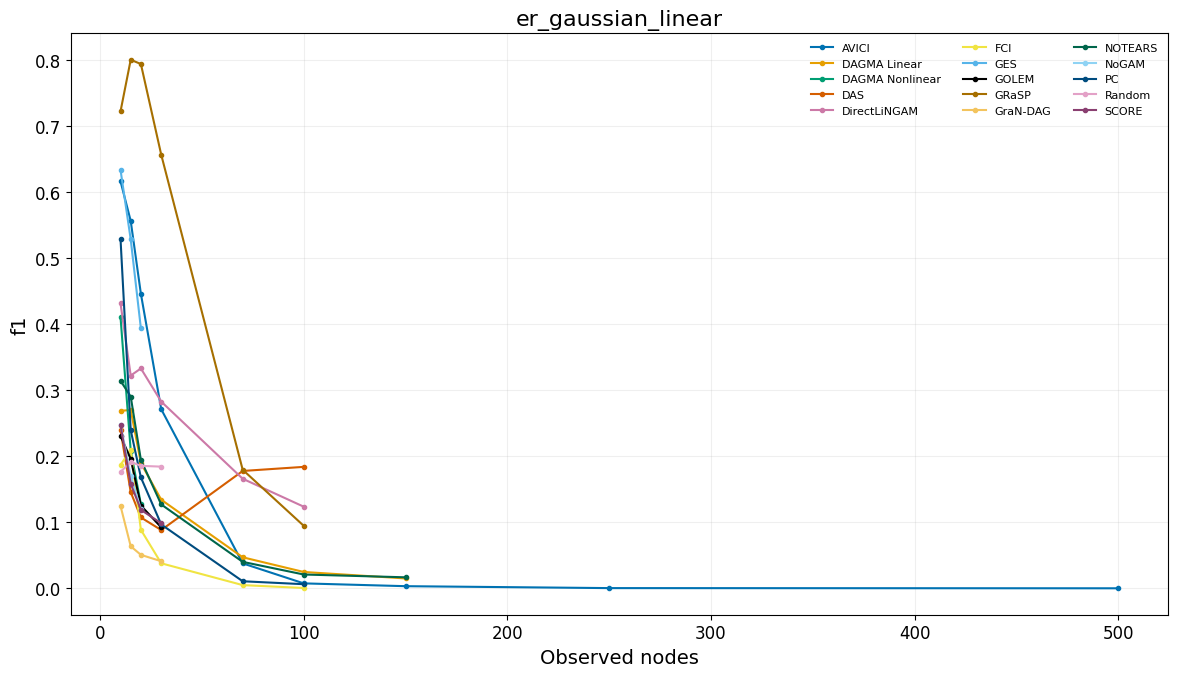

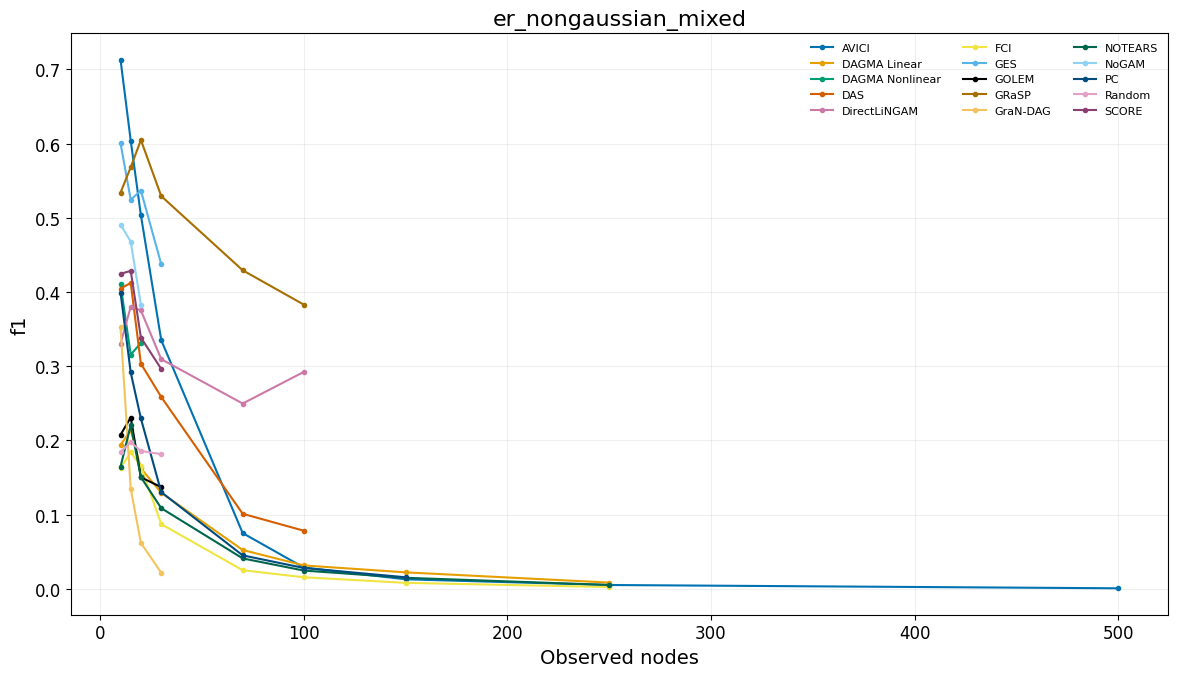

,scalability_family,n_nodes,model,mean,std,size
0,er_gaussian_linear,10.0,AVICI,134.321636,0.699079,15
1,er_gaussian_linear,10.0,DAGMA_Linear,12.667524,1.914128,15
2,er_gaussian_linear,10.0,DAGMA_Nonlinear,785.668178,11.219803,15
3,er_gaussian_linear,10.0,DAS,61.910240,0.534461,15
4,er_gaussian_linear,10.0,DirectLiNGAM,2.429996,0.098605,15
5,er_gaussian_linear,10.0,FCI,2.254200,0.201726,15
6,er_gaussian_linear,10.0,GES,0.957822,0.470077,15
7,er_gaussian_linear,10.0,GOLEM,866.290142,8.281253,15
8,er_gaussian_linear,10.0,GRaSP,0.310916,0.068453,15
9,er_gaussian_linear,10.0,GraNDAG,420.553671,3.202675,15


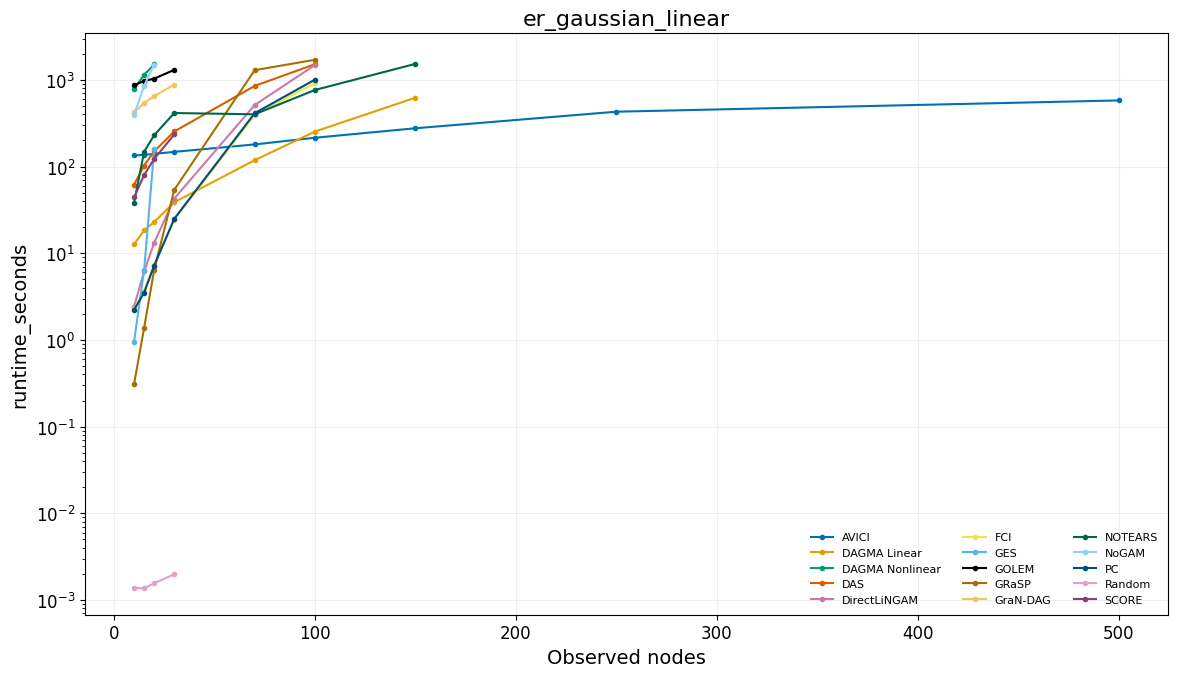

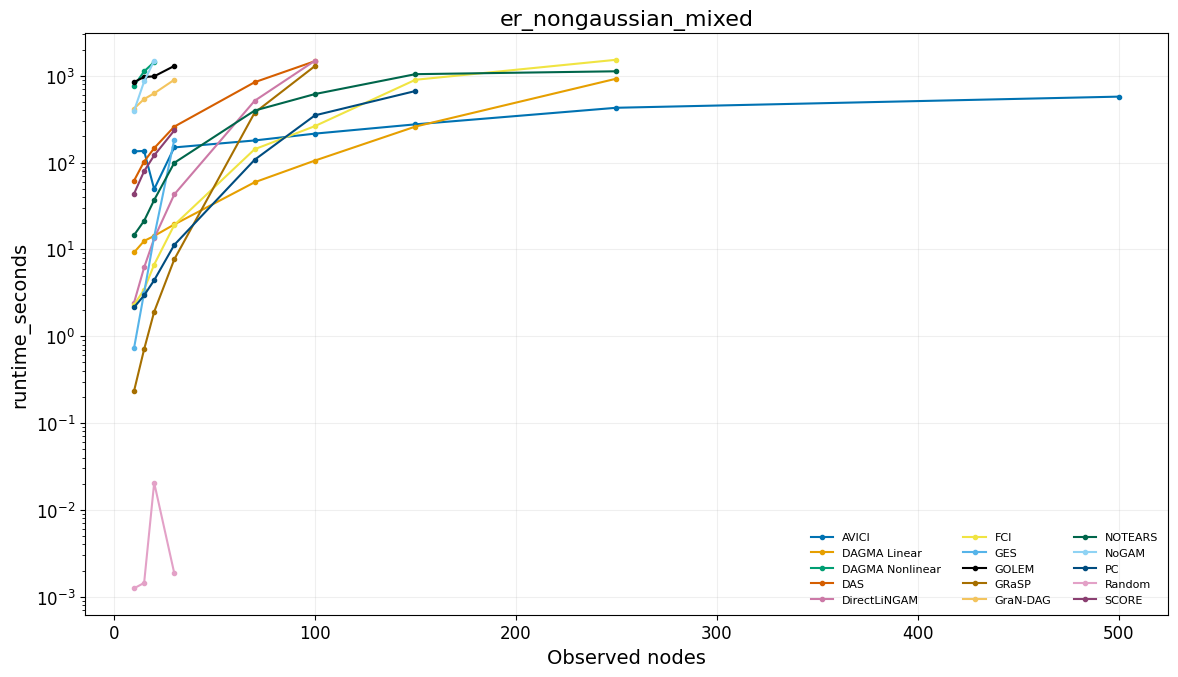

In [12]:
metric_summaries = pd.read_pickle(ROOT / "results/analysis/scalability.pkl")["metric_summaries"]
for metric in ('f1', 'runtime_seconds'):
    summary = metric_summaries[metric]
    display(summary.head(20))
    for family, g in summary.groupby('scalability_family'):
        fig, ax = plt.subplots(figsize=(12, 7))
        for model, series in g.groupby('model'):
            series = series.sort_values('n_nodes')
            ax.plot(series.n_nodes, series['mean'], marker='o', label=th.model_label(model), markersize=3)
        ax.set(xlabel='Observed nodes', ylabel=metric, title=family)
        if metric == 'runtime_seconds':
            ax.set_yscale('log')
        ax.legend(fontsize=8, ncol=3)
        ax.grid(alpha=0.2)
        fig.tight_layout()
        display(fig)
        plt.close(fig)
